# Quantum error correction, and the heat engine a quantum computer lives in
### parity checks · logical error rates in SymPy · Hamming/Steane over GF(2) · a graph-matching decoder with a measured threshold · Carnot integrals

**In plain words.** Qubits make mistakes, roughly one per thousand operations on good hardware
today. Useful algorithms need about one per trillion. Quantum error correction (QEC) closes that
gap by spreading one *logical* qubit over many *physical* ones and repeatedly checking
**parities**, never the data itself, since that would destroy the quantum state.

**Two engineering realities follow:**
* Decoding the parity results is a **graph problem**, and it has to run in real time. That's where
  computer science and design automation enter quantum computing.
* Every check cycle pumps entropy out of the qubits, and the refrigerator has to pump that heat out
  of the cryostat. A quantum computer is a **heat-engine problem**.

Everything here uses free software (numpy, sympy, networkx) and synthetic Monte Carlo. Every
figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as well as
color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import quantum_error_correction as q
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. The bit-flip code: measure parities, not data

Encode $\alpha|0\rangle+\beta|1\rangle\to\alpha|000\rangle+\beta|111\rangle$. The
**stabilizers** $Z_1Z_2$ and $Z_2Z_3$ ask "do qubits 1 and 2 agree?" and "do qubits 2 and 3
agree?". Each answer is $\pm1$, and neither reveals $\alpha$ or $\beta$. The pattern of answers,
the **syndrome**, points to the flipped qubit:

In [2]:
for err, syn in q.syndrome_table().items():
    print(f"{err:14s} -> syndrome {syn}  -> correct qubit {q.correction_for(syn)}")

none           -> syndrome (1, 1)  -> correct qubit None
X on qubit 0   -> syndrome (-1, 1)  -> correct qubit 0
X on qubit 1   -> syndrome (-1, -1)  -> correct qubit 1
X on qubit 2   -> syndrome (1, -1)  -> correct qubit 2


This is triple modular redundancy (TMR) from fault-tolerant computer engineering, with one
quantum twist: you vote on **parities**, so the superposition survives.

*(A note on the repo's own code: `dgs.quantum_ce.three_qubit_bit_flip_code` labels these
syndromes inconsistently. Its lookup dict maps $(-1,+1)$ to qubit 1 and duplicates a key. The table
above is computed directly. A separate fix has been suggested.)*

## 2. When does the code help? Logical error rate in SymPy

Each qubit flips independently with probability $p$. The code fails only if 2 or more flip:

In [3]:
p = sp.symbols("p", positive=True)
for d in (3, 5, 7):
    display(sp.Eq(sp.Symbol(f"p_L(d={d})"), q.logical_error_symbolic(d)))
print("code helps for p below:", q.code_capacity_crossover())

code helps for p below: [1/2]


state-vector Monte Carlo at p = 0.1: logical failure 0.0287  vs formula 0.0280
(1 - average fidelity = 0.0023: a logical X_L leaves a state that can still overlap the original -- counting failures by fidelity under-counts them)


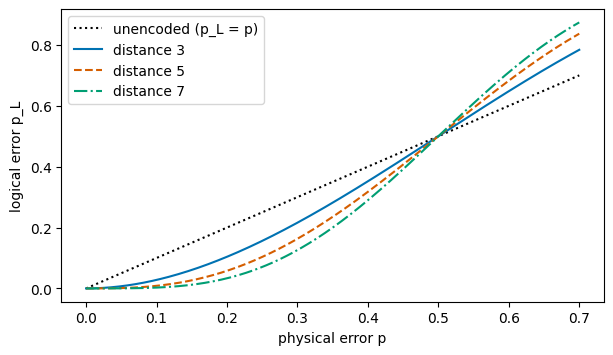

Figure description: logical error versus physical error for distance 3 (solid), 5 (dashed), 7 (dash-dot) and the unencoded line (dotted). All cross at p = 1/2; below it, larger codes have lower logical error.


In [4]:
res = [q.run_bit_flip(0.6, 0.8, 0.1, rng=i) for i in range(20000)]
fails = np.mean([e for _, e in res]); one_minus_F = 1 - np.mean([f for f, _ in res])
print(f"state-vector Monte Carlo at p = 0.1: logical failure {fails:.4f}  vs formula {q.logical_error(0.1, 3):.4f}")
print(f"(1 - average fidelity = {one_minus_F:.4f}: a logical X_L leaves a state that can still overlap the original -- "
      "counting failures by fidelity under-counts them)")
pp = np.linspace(0, 0.7, 300)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(pp, pp, "k:", label="unencoded (p_L = p)")
for d, ls in ((3, "-"), (5, "--"), (7, "-.")):
    ax.plot(pp, [q.logical_error(x, d) for x in pp], ls=ls, label=f"distance {d}")
ax.set_xlabel("physical error p"); ax.set_ylabel("logical error p_L"); ax.legend(); plt.show()
print("Figure description: logical error versus physical error for distance 3 (solid), 5 (dashed), 7 (dash-dot) and "
      "the unencoded line (dotted). All cross at p = 1/2; below it, larger codes have lower logical error.")

Below the crossover, adding qubits **exponentially** suppresses errors: $p_L\sim p^{(d+1)/2}$.
Above it, adding qubits makes things worse. That crossover is a **threshold**, the most important
number in fault-tolerant quantum computing.

## 3. Phase flips, and Hamming/Steane over GF(2)

Qubits also suffer **phase flips** ($Z$ errors), which the bit-flip code can't see. Hadamards swap
the two kinds:

In [5]:
a, b = q.hadamard_conjugation_check()
print("H X H - Z =", a.tolist(), "   H Z H - X =", b.tolist())

H X H - Z = [[0, 0], [0, 0]]    H Z H - X = [[0, 0], [0, 0]]


So the phase-flip code is the bit-flip code in the Hadamard basis, with stabilizers $X_1X_2$
and $X_2X_3$. To catch both kinds at once, borrow a classical code. The **Hamming [7,4]** parity-check
matrix has the numbers 1–7 in binary as its columns, so the syndrome of a single error **is** its
position:

In [6]:
Hm = q.hamming_parity_check(); print("H =\n", Hm)
print("syndrome of a single error at positions 1..7:", [q.hamming_syndrome(np.eye(7, dtype=int)[j]) for j in range(7)])
cw = q.hamming_codewords(); print(f"{len(cw)} codewords (null space over GF(2)), minimum distance {q.min_distance(cw)}")
print("H H^T mod 2 =\n", q.steane_check_commutation(), " -> Steane's X- and Z-type checks commute")

H =
 [[0 0 0 1 1 1 1]
 [0 1 1 0 0 1 1]
 [1 0 1 0 1 0 1]]
syndrome of a single error at positions 1..7: [1, 2, 3, 4, 5, 6, 7]
16 codewords (null space over GF(2)), minimum distance 3
H H^T mod 2 =
 [[0 0 0]
 [0 0 0]
 [0 0 0]]  -> Steane's X- and Z-type checks commute


The **Steane code** uses the same matrix twice: once for $Z$-type checks (catching $X$ errors)
and once for $X$-type checks (catching $Z$ errors). They can be measured together because
$HH^T=0$ over GF(2): every pair of rows overlaps on an even number of qubits. It's linear algebra
over bits, the same GF(2) arithmetic as `dgs.gf2_polynomials` and CRC checks.

## 4. Decoding is a graph problem: matching, with noisy measurements

Real syndrome measurements are themselves faulty. So you repeat them for $d$ rounds and look for
**detection events**, places where a parity *changes* between rounds. A data error makes a pair of
events in space; a measurement error makes a pair in time. The decoder pairs up all events by
**minimum-weight perfect matching** (via networkx), with edge weights equal to space-time distance,
and flips the qubits along each matched path. The physical error rate $p$ is applied to both data
and measurements:

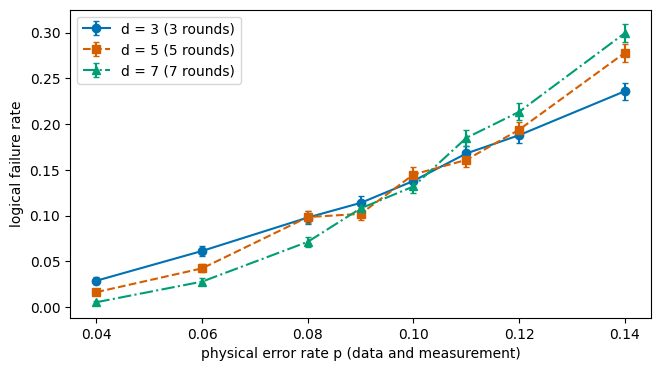

d=3: 0.029  0.061  0.098  0.114  0.138  0.168  0.188  0.236
d=5: 0.017  0.043  0.099  0.102  0.145  0.161  0.194  0.278
d=7: 0.005  0.028  0.071  0.108  0.132  0.185  0.213  0.299
Figure description: logical failure rate versus physical error rate for distances 3, 5, 7 (solid/circles, dashed/squares, dash-dot/triangles, with binomial error bars). At low p the d = 7 curve is lowest; the curves cross near p = 0.10 (0.09-0.11 across runs), above which larger codes fail more often.


In [7]:
ps, out = q.threshold_sweep(ds=(3, 5, 7), ps=(0.04, 0.06, 0.08, 0.09, 0.10, 0.11, 0.12, 0.14), trials=2000, seed=1)
fig, ax = plt.subplots(figsize=(7.5, 4))
for (d, v), ls, mk in zip(out.items(), ("-", "--", "-."), ("o", "s", "^")):
    err = np.sqrt(np.array(v) * (1 - np.array(v)) / 2000)
    ax.errorbar(ps, v, yerr=err, ls=ls, marker=mk, capsize=2, label=f"d = {d} ({d} rounds)")
ax.set_xlabel("physical error rate p (data and measurement)"); ax.set_ylabel("logical failure rate"); ax.legend(); plt.show()
for d, v in out.items():
    print(f"d={d}: " + "  ".join(f"{x:.3f}" for x in v))
print("Figure description: logical failure rate versus physical error rate for distances 3, 5, 7 (solid/circles, "
      "dashed/squares, dash-dot/triangles, with binomial error bars). At low p the d = 7 curve is lowest; the curves cross "
      "near p = 0.10 (0.09-0.11 across runs), above which larger codes fail more often.")

The curves cross near **10%** (between 0.09 and 0.11 across Monte Carlo runs). That is the threshold for this repetition code with noisy
measurements, consistent with the roughly 10% reported for this noise model. The surface code,
which protects against both $X$ and $Z$ errors, has a threshold near 1% under realistic circuit
noise. That's why hardware groups work so hard to push two-qubit gate errors below 1%.

**Why this is design automation:**
* The decoder must keep up with a measurement cycle of about a microsecond.
* Matching graphs grow with $d^2\times$rounds.
* Real decoders run on FPGAs or ASICs, a computer-engineering problem.

## 5. How many qubits? The overhead

A widely used surface-code heuristic is $p_L\approx A\,(p/p_{th})^{(d+1)/2}$, with a rotated
surface code using $2d^2-1$ physical qubits per logical qubit:

In [8]:
print(f"{'p (physical)':>13s} {'target p_L':>11s} {'distance d':>11s} {'qubits / logical':>17s}")
for p_ in (5e-3, 1e-3, 1e-4):
    for tgt in (1e-6, 1e-12):
        d_ = q.surface_code_distance(p_, tgt)
        print(f"{p_:13.0e} {tgt:11.0e} {d_:11d} {q.surface_code_qubits(d_):17,d}")
print("\n(heuristic with A = 0.1, p_th = 1%; real overheads depend on the hardware's noise and the decoder)")

 p (physical)  target p_L  distance d  qubits / logical
        5e-03       1e-06          33             2,177
        5e-03       1e-12          73            10,657
        1e-03       1e-06          11               241
        1e-03       1e-12          23             1,057
        1e-04       1e-06           5                49
        1e-04       1e-12          11               241

(heuristic with A = 0.1, p_th = 1%; real overheads depend on the hardware's noise and the decoder)


Halving the physical error rate saves far more qubits than any clever trick later on. **Better
hardware is the cheapest error correction.**

## 6. The heat engine: Carnot integrals and the refrigerator

Error correction moves entropy out of the qubits, and the second law says that entropy ends up as
heat somewhere. Start with the Carnot cycle. SymPy integrates $\int p\,dV$ for an ideal gas
along the two isotherms, using $TV^{\gamma-1}=$ const on the adiabats:

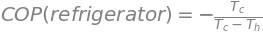

In [9]:
Qh, Qc, eta = q.carnot_cycle_symbolic()
display(sp.Eq(sp.Symbol("Q_h"), Qh), sp.Eq(sp.Symbol("Q_c"), Qc), sp.Eq(sp.Symbol("eta"), eta))
display(sp.Eq(sp.Symbol("COP (refrigerator)"), q.carnot_cop_symbolic()))

Run it backwards and you have a refrigerator. Its best possible coefficient of performance is
$T_c/(T_h-T_c)$. At the millikelvin stage that number is tiny:

In [10]:
for Tc in (4.0, 1.0, 0.1, 0.02):
    print(f"remove 1 uW at {Tc:5.2f} K from 300 K: ideal wall power >= {q.wall_power_for_cooling(1e-6, Tc)*1e3:9.3f} mW")
H_L = q.qec_landauer_heat(n_logical=1000, d=23, cycle_hz=1e6, T_c=0.02)
print(f"\nLandauer floor for resetting syndrome ancillas (1000 logical qubits, d = 23, 1 MHz cycles, 20 mK): {H_L:.2e} W")

remove 1 uW at  4.00 K from 300 K: ideal wall power >=     0.074 mW
remove 1 uW at  1.00 K from 300 K: ideal wall power >=     0.299 mW
remove 1 uW at  0.10 K from 300 K: ideal wall power >=     2.999 mW
remove 1 uW at  0.02 K from 300 K: ideal wall power >=    14.999 mW

Landauer floor for resetting syndrome ancillas (1000 logical qubits, d = 23, 1 MHz cycles, 20 mK): 1.01e-13 W


Two lessons:
* **The Carnot penalty is huge at millikelvin.** Each microwatt removed at 20 mK costs at least
  15 mW at room temperature even for a perfect refrigerator. Real cryostats are far less efficient:
  the pulse-tube compressor alone draws kilowatts of wall power to provide microwatt-scale cooling
  at the coldest stage.
* **Landauer's floor is not the problem.** Erasing syndrome bits costs about $10^{-13}$ W, orders
  of magnitude below the coldest stage's cooling power. The real heat loads are wiring, control
  signals, and readout amplifiers. That's why cryogenic control electronics are a major
  computer-engineering research area.

## 7. Summary

| topic | result |
|---|---|
| bit-flip code | syndromes $(\pm1,\pm1)$ locate one X error; parities, not data |
| logical error | $p_L=3p^2-2p^3$ (d=3); Monte Carlo 0.029 vs formula 0.028 at p=0.1 |
| phase flips | $HXH=Z$: same code in the Hadamard basis |
| Hamming/Steane | syndrome = error position; 16 codewords, distance 3; $HH^T=0$ over GF(2) |
| decoding | space-time matching graph (networkx); threshold ≈ 10% (0.09–0.11) with noisy measurements |
| overhead | $2d^2-1$ qubits per logical; e.g. ~1,000 at $p=10^{-3}$ for $p_L=10^{-12}$ (heuristic) |
| heat engine | $\eta=1-T_c/T_h$; COP $=T_c/(T_h-T_c)$; 1 µW at 20 mK needs ≥ 15 mW at 300 K |

**Connections to the rest of the repo:**
* thermal qubits and Landauer: `stat_thermo_qis`;
* GF(2) arithmetic: `gf2_polynomials`;
* graphs and critical paths: `qis_pathway_planning`, `logic_timing`;
* the phase errors QEC fights: `dephasing_phase_retrieval`.

*Synthetic Monte Carlo; heuristics labeled as such. Education.*